# 銘柄レベルの時系列特性とリードラグ

**目的**: ファクターの横断面（どの銘柄が勝つか）を、銘柄リターンの**時系列の性質**（自己相関、他銘柄・市場・業種への遅れ、
日中と夜間の分かれ方、出来高）から見直す。既存の `core` 123 本は主に「水準」の特性（mom1、mom12_1、tover、vola60、skew60 など）で、
時系列の構造そのものから作った特性は少ない。ここで「時系列由来の新しい銘柄特性」の候補を洗い出す。

**問いと予測**（文献での結果。インドで同じかを見る）

| § | 問い | 文献の予測 |
| --- | --- | --- |
| 1 | 月次リターンのラグ構造。年周期（12・24・36 か月前）のラグは周りより強いか | Heston–Sadka: 同じ暦月の過去リターンが正に効く（季節性） |
| 1 | 日次・週次のリバーサルの強さはサイズでどう違うか | 小型ほど強い（ビッド・アスク、流動性提供の対価） |
| 2 | 相対強度の利益は「自己相関（時系列）」「リードラグ（交差自己相関）」「平均リターンの差」のどれから来るか | Lo–MacKinlay: 週次の逆張り利益の多くはリードラグ。Lewellen: 12 か月モメンタムは交差項 |
| 3 | 大型株が小型株を先行するか。業種は銘柄を先行するか | Lo–MacKinlay、Hou (2007): 大型 → 小型、業種内の大企業 → 小企業 |
| 4 | 市場ニュースへの反応が遅い銘柄（価格遅延 D1）は報われるか | Hou–Moskowitz: 遅延の大きい銘柄にプレミアム（主に小型） |
| 5 | オーバーナイトと日中のリターンは別々に持続・反転するか | Lou–Polk–Skouras: オーバーナイトは持続、日中は反転（綱引き） |
| 6 | 出来高・極端値 | 高出来高プレミアム（Gervais–Kaniel–Mingelgrin）、MAX は負（Bali ほか）、52 週高値に近いほど正（George–Hwang） |

**設計**

- 評価は月次の Fama–MacBeth（FM）と等ウェイト Q5−Q1。説明変数は各月末 $t$ のユニバース内で順位 → 標準化（平均 0・標準偏差 1）し、
  翌月 $t+1$ の `drtn`（配当込み）と GEMLT の `srtn`（固有）を被説明変数にする。係数は「1 標準偏差あたりの翌月リターン（%/月）」。
- サイズ区分（MSCI の大型・中型・小型）別は、区分内で順位を付け直した FM の t 値。
- t 値は Newey–West（月次 3 ラグ、週次・日次 5 ラグ）。IS = リターン月 2008〜2017、OOS = 2018〜2026-07。
- 既存の `core`（mom1、mom12_1、tover、vola60、skew60）と log 時価総額を同時に入れた FM で残るかも確認する。
- 多重検定: 本ノートでは 10 本前後の特性と多数のラグを見る。|t| ≥ 3 かつ IS・OOS で同符号のものだけを「候補」とみなす。

**規約**: 月末 $t$ のユニバース（`data/universe`）の銘柄が対象。日次・週次はその月 $t+1$ の各営業日の構成銘柄
（`panel.member_daily`）。月次・週次の価格リターンは日次（終値、配当なし）の複利で、ユニバース外の期間の過去データも特性の計算に使う。
主サンプルは 2008-01〜2026-07。

In [1]:
import sys
from pathlib import Path

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../../scripts").resolve()))
from build_market_panel import SECTOR_NAMES, SIZE_NAMES, load_panel

from alphaeval import InputStore

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

PANEL_DIR = "../../data/market_panel"
INPUT_ROOT = "../../input/msci_india_imi"
SIG_START, SIG_END = "2007-12-31", "2026-06-30"  # シグナルの月末 t（リターンは t+1）
IS_LAST_SIGNAL = pd.Timestamp("2017-11-30")  # リターン月 2017-12 まで = IS
SUBPERIODS = [("2008", "2012"), ("2013", "2017"), ("2018", "2021"), ("2022", "2026")]

panel = load_panel(PANEL_DIR, fields=("ret", "ret_on", "ret_id", "turnover", "close"))
store = InputStore(INPUT_ROOT)
ret_d = panel.daily["ret"]
mem_d = panel.member_daily("cap").notna()
size_d = panel.member_daily("size")
sector_d = panel.member_daily("sector")
cap_m, size_m, drtn = panel.monthly["cap"], panel.monthly["size"], panel.monthly["drtn"]
COLS = cap_m.columns
srtn = store.returns("GEMLT", "srtn", 200712, 202607).reindex(columns=COLS)
months = cap_m.loc[SIG_START:SIG_END].index


def on_months(df: pd.DataFrame) -> pd.DataFrame:
    return df.reindex(index=months, columns=COLS)


U = on_months(cap_m.notna()).fillna(False).astype(bool)  # 月末 t の構成
SIZE = on_months(size_m)
FWD = {
    "drtn": on_months(drtn.shift(-1)),
    "srtn": on_months(srtn.reindex(index=drtn.index).shift(-1)),
}
IS = months <= IS_LAST_SIGNAL


def period_returns(r: pd.DataFrame, freq: str) -> pd.DataFrame:
    # 日次リターンを期間（"M" = 月末、"W-FRI" = 金曜終わりの週）で複利合成する（全欠損は NaN）
    out = np.expm1(np.log1p(r).resample(freq).sum(min_count=1))
    return out


mret = period_returns(ret_d, "M")  # 月次の価格リターン（全期間、全銘柄）
print(
    "月数",
    len(months),
    months[0].date(),
    "〜",
    months[-1].date(),
    "／ 構成銘柄数（平均）",
    int(U.sum(axis=1).mean()),
)

月数 223 2007-12-31 〜 2026-06-30 ／ 構成銘柄数（平均） 373


In [2]:
def zrank(x: pd.DataFrame, mask: pd.DataFrame) -> pd.DataFrame:
    # 行ごとにマスク内で順位を付け、平均 0・標準偏差 1 に標準化する
    r = x.where(mask).rank(axis=1)
    return r.sub(r.mean(axis=1), axis=0).div(r.std(axis=1), axis=0)


def cs_slope(z: pd.DataFrame, y: pd.DataFrame, min_n: int = 30) -> pd.Series:
    # 行ごとの単回帰（切片あり）の傾き。z と y がともに有効な銘柄のみ
    valid = z.notna() & y.notna()
    zz, yy = z.where(valid), y.where(valid)
    zc = zz.sub(zz.mean(axis=1), axis=0)
    yc = yy.sub(yy.mean(axis=1), axis=0)
    b = (zc * yc).sum(axis=1) / (zc**2).sum(axis=1)
    return b.where(valid.sum(axis=1) >= min_n)


def fm_multi(
    zs: dict[str, pd.DataFrame], y: pd.DataFrame, min_n: int = 50
) -> pd.DataFrame:
    # 行ごとの重回帰（切片あり）の係数
    names = list(zs)
    X = np.stack([zs[n].reindex_like(y).to_numpy(float) for n in names], axis=2)
    Y = y.to_numpy(float)
    out = np.full((len(y), len(names)), np.nan)
    for t in range(len(y)):
        ok = np.isfinite(Y[t]) & np.isfinite(X[t]).all(axis=1)
        if ok.sum() < min_n:
            continue
        A = np.column_stack([np.ones(ok.sum()), X[t][ok]])
        out[t] = np.linalg.lstsq(A, Y[t][ok], rcond=None)[0][1:]
    return pd.DataFrame(out, index=y.index, columns=names)


def nw_t(x: pd.Series, lags: int = 3) -> float:
    # Newey–West（Bartlett）の t 値
    v = pd.Series(x).dropna().to_numpy(float)
    n = len(v)
    if n < 10:
        return np.nan
    e = v - v.mean()
    s = e @ e / n
    for lag in range(1, lags + 1):
        s += 2 * (1 - lag / (lags + 1)) * (e[lag:] @ e[:-lag]) / n
    return v.mean() / np.sqrt(s / n)


def q_spread(z: pd.DataFrame, y: pd.DataFrame, q: float = 0.2) -> pd.Series:
    # 等ウェイト Q5−Q1（中央順位 p = (rank − 0.5)/N、上位 p ≥ 1−q、下位 p < q）
    valid = z.notna() & y.notna()
    zz = z.where(valid)
    p = zz.rank(axis=1).sub(0.5).div(valid.sum(axis=1), axis=0)
    sp = y.where(p >= 1 - q).mean(axis=1) - y.where(p < q).mean(axis=1)
    return sp.where(valid.sum(axis=1) >= 30)


def evaluate(sig: pd.DataFrame, name: str) -> pd.Series:
    # FM（drtn / srtn、IS / OOS）、Q5−Q1、サイズ区分別の FM t 値
    s = on_months(sig)
    z = zrank(s, U)
    row = {}
    for rk in ("drtn", "srtn"):
        b = cs_slope(z, FWD[rk])
        row[f"{rk} FM%"] = b.mean() * 100
        row[f"{rk} t"] = nw_t(b)
        if rk == "drtn":
            row["IS t"] = nw_t(b[IS])
            row["OOS t"] = nw_t(b[~IS])
        sp = q_spread(z, FWD[rk])
        row[f"{rk} Q5−Q1 年%"] = sp.mean() * 1200
        row[f"{rk} Q t"] = nw_t(sp)
    for k, nm in SIZE_NAMES.items():
        bk = cs_slope(zrank(s, U & (SIZE == k)), FWD["drtn"], min_n=15)
        row[f"{nm} t"] = nw_t(bk)
    return pd.Series(row, name=name)

## 1. ラグ構造

### 1.1 月次リターンのラグ $k$ = 1〜36 か月

月末 $t$ に「$k$ か月前の月（月 $t-k+1$）の価格リターン」を単独で入れた FM の係数。$k=1$ は直近 1 か月（短期リバーサル）。
Heston–Sadka の季節性があれば、$k$ = 12, 24, 36（翌月と同じ暦月）で棒が周りより高くなる。

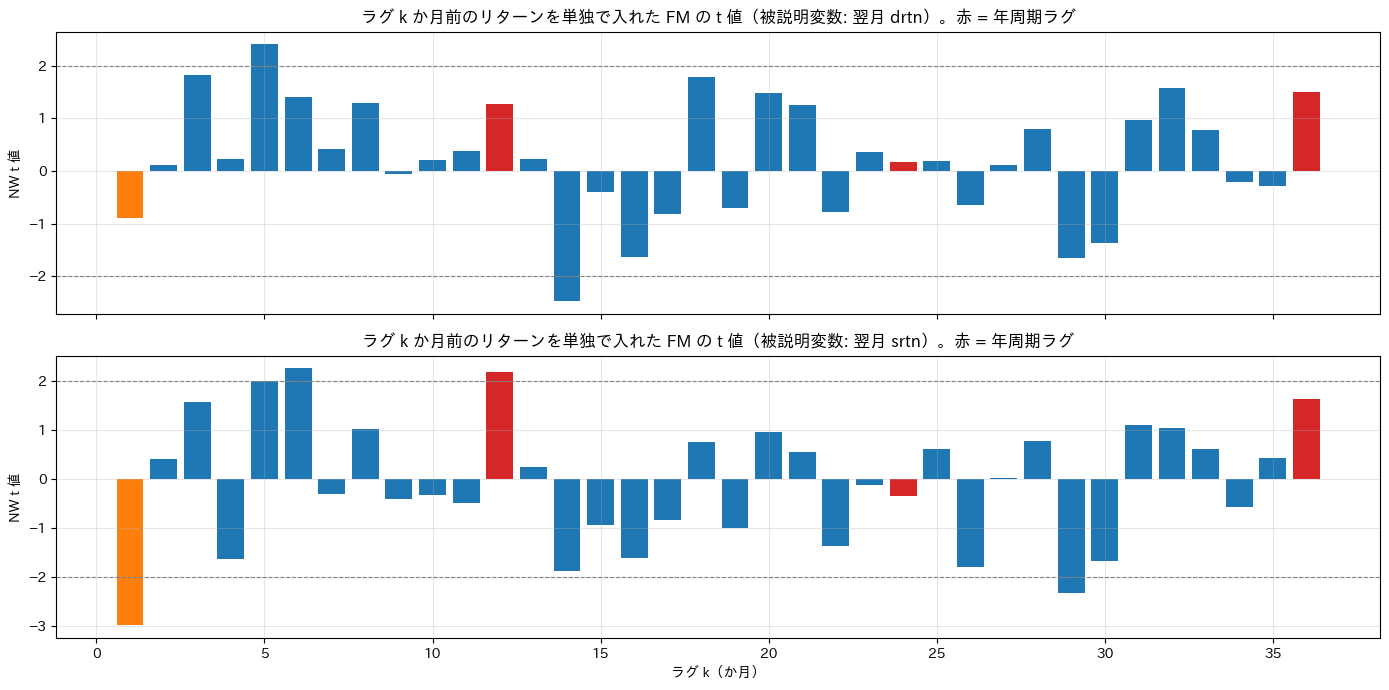

年周期ラグの平均 t（drtn）: 0.99 ／ 非年周期ラグ（2〜36、12 の倍数以外）: 0.21


drtn          srtn       
     coef      t   coef      t
1  -0.079 -0.885 -0.206 -2.993
2   0.010  0.113  0.025  0.391
3   0.207  1.828  0.122  1.571
6   0.158  1.399  0.136  2.247
11  0.037  0.385 -0.030 -0.486
12  0.114  1.273  0.140  2.165
13  0.016  0.228  0.013  0.230
23  0.027  0.371 -0.007 -0.129
24  0.014  0.181 -0.021 -0.344
25  0.015  0.186  0.037  0.598
35 -0.024 -0.292  0.026  0.425
36  0.121  1.511  0.095  1.623

In [3]:
lag_rows = {}
for k in range(1, 37):
    s = on_months(mret.shift(k - 1))
    z = zrank(s, U)
    rec = {}
    for rk in ("drtn", "srtn"):
        b = cs_slope(z, FWD[rk])
        rec[(rk, "coef")] = b.mean() * 100
        rec[(rk, "t")] = nw_t(b)
    lag_rows[k] = rec
lag_tbl = pd.DataFrame(lag_rows).T

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, rk in zip(axes, ("drtn", "srtn")):
    t = lag_tbl[(rk, "t")]
    colors = ["C3" if k % 12 == 0 else ("C1" if k == 1 else "C0") for k in t.index]
    ax.bar(t.index, t, color=colors)
    for h in (-2, 2):
        ax.axhline(h, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(
        f"ラグ k か月前のリターンを単独で入れた FM の t 値（被説明変数: 翌月 {rk}）。赤 = 年周期ラグ"
    )
    ax.set_ylabel("NW t 値")
axes[1].set_xlabel("ラグ k（か月）")
plt.tight_layout()
plt.show()

annual = [12, 24, 36]
others = [k for k in range(2, 37) if k % 12 != 0]
print(
    "年周期ラグの平均 t（drtn）:",
    round(lag_tbl.loc[annual, ("drtn", "t")].mean(), 2),
    "／ 非年周期ラグ（2〜36、12 の倍数以外）:",
    round(lag_tbl.loc[others, ("drtn", "t")].mean(), 2),
)
display(lag_tbl.loc[[1, 2, 3, 6, 11, 12, 13, 23, 24, 25, 35, 36]].round(3))

### 1.2 季節性シグナル（同じ暦月の過去リターンの平均）

Heston–Sadka に倣い、ラグ 12・24・36・48・60 か月（翌月と同じ暦月）のリターンの平均を特性 `seas` とする（2 年分以上あれば計算）。
比較用に、非年周期ラグ 2〜11 か月の平均（`nonseas_2_11`、ほぼ mom12_1）も評価する。

In [4]:
annual_lags = [mret.shift(k - 1) for k in (12, 24, 36, 48, 60)]
cnt = sum(a.notna().astype(int) for a in annual_lags)
seas = (sum(a.fillna(0) for a in annual_lags) / cnt).where(cnt >= 2)
nonseas = mret.shift(1).rolling(10, min_periods=8).mean()  # ラグ 2〜11
SIG = {}  # 候補特性（月末 t、全銘柄）
SIG["rev1（直近 1 か月）"] = mret
SIG["seas（同月の過去平均）"] = seas
res_lag = pd.DataFrame(
    [
        evaluate(mret, "rev1（直近 1 か月）"),
        evaluate(seas, "seas（同月の過去平均）"),
        evaluate(nonseas, "nonseas_2_11"),
    ]
)
display(res_lag.round(2))

,drtn FM%,drtn t,IS t,OOS t,drtn Q5−Q1 年%,drtn Q t,srtn FM%,srtn t,srtn Q5−Q1 年%,srtn Q t,large t,mid t,small t
rev1（直近 1 か月）,-0.08,-0.88,0.37,-2.05,-2.30,-0.76,-0.21,-2.99,-6.20,-2.54,-1.30,-2.45,-0.24
seas（同月の過去平均）,0.09,1.09,0.30,1.33,3.20,1.08,0.10,1.50,3.42,1.47,0.95,0.72,0.75
nonseas_2_11,0.19,1.26,-0.14,3.38,5.81,1.16,0.06,0.74,1.32,0.45,-0.45,0.01,1.70


### 1.3 日次・週次のリバーサル（サイズ別、期間別）

日次: 営業日 $d-1$ のリターン（構成銘柄内で標準化）で営業日 $d$ のリターンを回帰した傾き（bp / 1 標準偏差）。週次は金曜終わりの週。
区分内で順位を付け直している。負が大きいほど短期リバーサルが強い。

全期間 bp    t  2008-12  2013-17  2018-21  2022-26
頻度 区分                                                    
日次 all       3.0  6.6      5.1      2.6      5.6     -1.1
   large     1.5  2.3      5.3     -1.4     -0.6      2.3
   mid       0.3  0.4      3.7     -2.6      0.1     -0.2
   small     3.6  7.2      5.1      3.9      7.5     -1.8
週次 all      -8.0 -3.2    -11.5     -6.1     -1.5    -11.9
   large   -16.7 -5.0    -28.2    -21.4    -11.0     -3.9
   mid     -13.0 -3.2    -19.4     -8.9     -7.3    -15.5
   small    -5.2 -2.0     -6.6     -1.9      0.8    -12.5

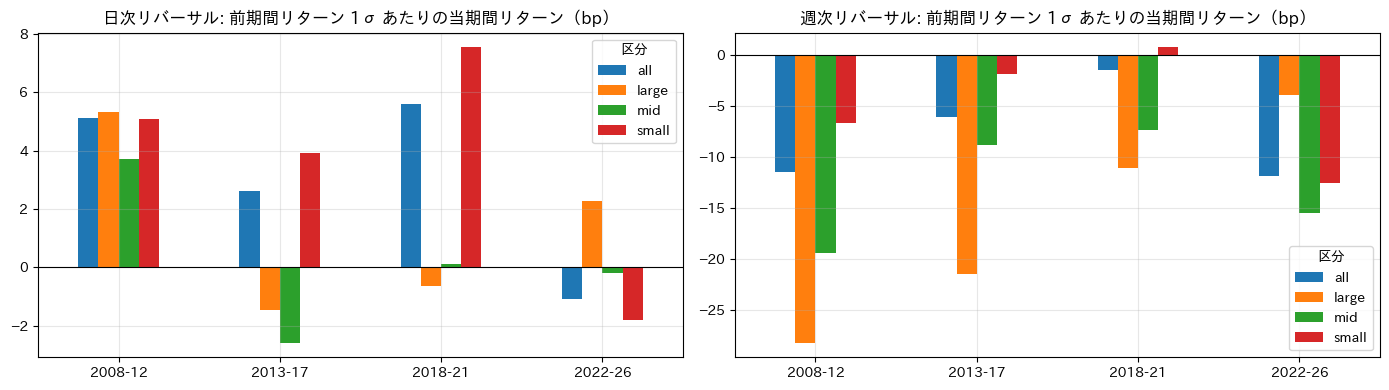

In [5]:
wret = period_returns(ret_d, "W-FRI")
wk_idx = wret.index
mem_w = mem_d.reindex(wk_idx, method="ffill").fillna(False).astype(bool)
size_w = size_d.reindex(wk_idx, method="ffill")
sector_w = sector_d.reindex(wk_idx, method="ffill")
ret_d8 = ret_d.loc["2008":]
mem_d8, size_d8 = mem_d.loc["2008":], size_d.loc["2008":]


def reversal_slopes(
    r: pd.DataFrame, mem: pd.DataFrame, sz: pd.DataFrame
) -> dict[str, pd.Series]:
    lagged = r.shift(1)
    out = {"all": cs_slope(zrank(lagged, mem), r)}
    for k, nm in SIZE_NAMES.items():
        out[nm] = cs_slope(zrank(lagged, mem & (sz == k)), r, min_n=15)
    return out


rev_d = reversal_slopes(ret_d8, mem_d8, size_d8)
rev_w = reversal_slopes(wret.loc["2008":], mem_w.loc["2008":], size_w.loc["2008":])
rows = []
for freq, dct, lags in (("日次", rev_d, 5), ("週次", rev_w, 5)):
    for nm, b in dct.items():
        rec = {
            "頻度": freq,
            "区分": nm,
            "全期間 bp": b.mean() * 1e4,
            "t": nw_t(b, lags),
        }
        for a, e in SUBPERIODS:
            rec[f"{a}-{e[2:]}"] = b.loc[a:e].mean() * 1e4
        rows.append(rec)
rev_tbl = pd.DataFrame(rows).set_index(["頻度", "区分"])
display(rev_tbl.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, freq in zip(axes, ("日次", "週次")):
    rev_tbl.loc[freq, [f"{a}-{e[2:]}" for a, e in SUBPERIODS]].T.plot.bar(ax=ax, rot=0)
    ax.set_title(f"{freq}リバーサル: 前期間リターン 1σ あたりの当期間リターン（bp）")
    ax.axhline(0, color="k", linewidth=0.8)
plt.tight_layout()
plt.show()

## 2. Lo–MacKinlay の分解: 横断面の利益を時系列の成分に分ける

相対強度ポートフォリオ $w_{i,t} = \frac{1}{N}(x_{i,t} - \bar x_t)$（$x$ = 形成期間のリターン）の翌期の利益
$\pi_{t+1} = \sum_i w_{i,t} r_{i,t+1}$ の期待値は、バランスパネル（期間中ずっと値のある $N$ 銘柄）で厳密に

$$
E[\pi] = \underbrace{\tfrac{N-1}{N^2}\textstyle\sum_i \mathrm{cov}(x_i, r_i)}_{O:\ 自己共分散（時系列）}
\;\underbrace{-\;\tfrac{1}{N^2}\textstyle\sum_{i \ne j} \mathrm{cov}(x_i, r_j)}_{C:\ 交差自己共分散（リードラグ）}
\;+\;\underbrace{\tfrac{1}{N}\textstyle\sum_i (\mu^x_i - \bar\mu^x)(\mu_i - \bar\mu)}_{D:\ 平均リターンの横断面の差}
$$

と分かれる（$\sum_{i\ne j}\mathrm{cov}(x_i,r_j) = N^2\,\mathrm{cov}(\bar x,\bar r) - \sum_i \mathrm{cov}(x_i,r_i)$ で計算）。

- $O > 0$: 銘柄が自分の過去に続く（**時系列モメンタム**）。$O < 0$ は時系列リバーサル。
- $C < 0$: ある銘柄の過去が他の銘柄の将来を正に予測する（**リードラグ**）。これはモメンタムの利益を減らし、逆張りの利益になる。
- $D$: 平均リターンが高い銘柄は過去リターンも高い、というだけで生じる利益（予測可能性ではない）。

形成期間 $x$ は 3 通り: 週次（前週 → 翌週）、月次（前月 → 翌月）、12-1 か月（$t-11$〜$t-1$ 月 → $t+1$ 月、月次で重複なし）。
バランスパネルは各期間の直前の月末にユニバースに入っていて、形成期間を含めてリターンが全てある銘柄（期間内の生存バイアスは残る）。
単位はリターンの二乗 × $10^4$（大きさの比較用）。

**小標本バイアスの補正**: 各銘柄の平均を期間内の標本平均で置き換えると、$O$ は負に、$D$ は正に偏る（12-1 か月なら
およそ $\mp 11\sigma^2/T$。$T$ = 60 か月で $\pm 30 \times 10^{-4}$ 程度）。そこで期間内の時点（行）を全銘柄同時に復元抽出した系列で
同じ分解を 300 回行う。この世界では同時点の銘柄間相関と各銘柄のリターン分布は保たれ、系列の構造（自己相関・リードラグ）は無いので、
真の値は $O = C = 0$、$D$ = 長い経路（20,000 期）で計算した値。ブートストラップ平均と真の値の差をバイアスとして差し引く。

In [6]:
def lm_decomp(X: np.ndarray, R: np.ndarray) -> np.ndarray:
    # X: 形成期間リターン（T×N）、R: 翌期リターン（T×N）。母分散（T で割る）で E[π] = O + C + D が厳密に成り立つ
    # 戻り値: [O, C, D, γ_m]（×1e4）。γ_m は等ウェイト平均の X と R の共分散（市場レベルの自己共分散）
    T, N = R.shape
    mx, mr = X.mean(axis=0), R.mean(axis=0)
    cov_ii = ((X - mx) * (R - mr)).mean(axis=0)
    xb, rb = X.mean(axis=1), R.mean(axis=1)
    cov_m = ((xb - xb.mean()) * (rb - rb.mean())).mean()
    O = (N - 1) / N**2 * cov_ii.sum()
    C = -(cov_m - cov_ii.sum() / N**2)
    D = ((mx - mx.mean()) * (mr - mr.mean())).mean()
    return np.array([O, C, D, cov_m]) * 1e4


def lag1(r: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    return r[:-1], r[1:]


def form_12_1(r: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    # 目標期間 j に対して、j−12〜j−2 の 11 か月の複利リターン（直近 1 か月はスキップ）
    cs = np.vstack([np.zeros((1, r.shape[1])), np.cumsum(np.log1p(r), axis=0)])
    j = np.arange(12, len(r))
    return np.expm1(cs[j - 1] - cs[j - 12]), r[12:]


FORMS = {
    "週次（1 週 → 1 週）": (wret, 1, lag1),
    "月次（1 か月 → 1 か月）": (mret, 1, lag1),
    "12-1 か月 → 1 か月": (mret, 12, form_12_1),
}
N_BOOT = 300
LONG = 20000  # ブートストラップ世界の「真の」D を推定する長い経路の長さ
rng = np.random.default_rng(0)
lm_rows = []
for fname, (rr, L, build) in FORMS.items():
    for a, e in SUBPERIODS:
        pos = np.where(
            (rr.index >= pd.Timestamp(f"{a}-01-01"))
            & (rr.index <= pd.Timestamp(f"{e}-12-31"))
        )[0]
        r_ext = rr.iloc[pos[0] - L : pos[-1] + 1]
        start_me = cap_m.index[cap_m.index < pd.Timestamp(f"{a}-01-01")][-1]
        sz0 = size_m.loc[start_me]
        for seg, codes in (
            ("全銘柄", (1, 2, 3)),
            ("大型+中型", (1, 2)),
            ("小型", (3,)),
        ):
            cols = sz0.index[sz0.isin(codes)]
            cols = cols[r_ext[cols].notna().all().to_numpy()]
            if len(cols) < 20:
                continue
            arr = r_ext[cols].to_numpy(float)
            Tn = len(arr)
            act = lm_decomp(*build(arr))
            # 帰無: 時点（行）を全銘柄同時に復元抽出 → 同時点の相関と分布は保ち、系列の構造は無い世界
            boot = np.array(
                [lm_decomp(*build(arr[rng.integers(0, Tn, Tn)])) for _ in range(N_BOOT)]
            )
            true_d = lm_decomp(*build(arr[rng.integers(0, Tn, LONG)]))[
                2
            ]  # その世界の真の D
            bias = boot.mean(axis=0) - np.array([0.0, 0.0, true_d, 0.0])
            adj = act - bias
            oc_boot = boot[:, 0] + boot[:, 1]
            lm_rows.append(
                {
                    "形成": fname,
                    "期間": f"{a}-{e[2:]}",
                    "区分": seg,
                    "N": len(cols),
                    "T": Tn - L,
                    "O": act[0],
                    "C": act[1],
                    "D": act[2],
                    "E[π]": act[:3].sum(),
                    "O 補正": adj[0],
                    "C 補正": adj[1],
                    "D 補正": adj[2],
                    "O+C 補正": adj[0] + adj[1],
                    "E[π] 補正": adj[:3].sum(),
                    "γ_m": act[3],
                    "p(O)": np.mean(boot[:, 0] >= act[0]),
                    "p(C)": np.mean(boot[:, 1] >= act[1]),
                    "p(O+C)": np.mean(oc_boot >= act[0] + act[1]),
                }
            )
lm_tbl = (
    pd.DataFrame(lm_rows)
    .set_index(["形成", "区分", "期間"])
    .sort_index(level=[0, 1], sort_remaining=False)
)
display(lm_tbl.round(3))

N    T       O       C       D    E[π]    O 補正    C 補正    D 補正  O+C 補正  E[π] 補正     γ_m   p(O)   p(C)  p(O+C)
形成              区分    期間                                                                                                                      
12-1 か月 → 1 か月  全銘柄   2008-12  226   60 -80.491  62.778  20.657   2.944 -30.707  38.186  -2.898   7.479    4.581 -63.136  0.740  0.173   0.330
                      2013-17  256   60 -27.419  16.089  28.653  17.323   0.684  10.370   5.222  11.055   16.277 -16.197  0.440  0.230   0.093
                      2018-21  331   48   5.420  -9.805  27.004  22.618  48.716 -20.249  -6.057  28.467   22.410   9.822  0.087  0.843   0.037
                      2022-26  396   55 -21.012  10.607  21.589  11.184   4.710   5.367   1.425  10.077   11.502 -10.660  0.387  0.310   0.063
                大型+中型 2008-12   56   60 -78.660  51.853  11.356 -15.451 -44.356  35.349  -4.744  -9.007  -13.751 -53.283  0.863  0.133   0.787
                      2013-17   68   60 -21.445  10.279   8.006  -3.159   1.276   4.371  -8.007   5.647   -2.360 -10.599  0.463  0.363   0.290
                      2018-21   79   48 -26.961   7.822  16.213  -2.927   0.414  -0.182  -5.418   0.231   -5.186  -8.168  0.457  0.540   0.500
                      2022-26  102   55 -21.141  11.289   9.422  -0.430  -3.748   6.764  -3.416   3.016   -0.399 -11.498  0.647  0.173   0.337
                小型    2008-12  170   60 -80.622  65.556  23.542   8.476 -27.002  39.768  -2.194  12.767   10.573 -66.033  0.700  0.177   0.173
                      2013-17  188   60 -29.453  18.299  34.899  23.744  -0.793  12.623  10.216  11.831   22.046 -18.457  0.480  0.240   0.127
                      2018-21  252   48  15.638 -16.093  30.168  29.714  65.253 -28.639  -6.000  36.614   30.615  16.155  0.033  0.857   0.010
                      2022-26  294   55 -20.895  10.921  25.645  15.671   7.495   4.755   4.007  12.249   16.256 -10.992  0.323  0.390   0.070
月次（1 か月 → 1 か月） 全銘柄   2008-12  237   60  13.315 -20.115   2.148  -4.652  18.808 -23.329   0.228  -4.521   -4.293  20.171  0.170  0.930   0.893
                      2013-17  260   60   6.642  -6.182   2.349   2.809   9.803  -7.273   0.510   2.530    3.040   6.208  0.083  0.933   0.160
                      2018-21  340   48 -11.990   2.371   2.297  -7.322  -6.156   0.177  -0.671  -5.979   -6.650  -2.406  0.693  0.497   0.930
                      2022-26  410   55  -1.516  -1.270   1.977  -0.809   0.208  -1.734   0.586  -1.527   -0.940   1.266  0.463  0.680   0.793
                大型+中型 2008-12   58   60   6.030 -10.086   1.251  -2.805   9.405 -11.686  -0.264  -2.281   -2.545  10.192  0.250  0.853   0.717
                      2013-17   68   60   2.636  -1.584   0.637   1.689   4.589  -2.020  -0.700   2.569    1.869   1.624  0.243  0.703   0.203
                      2018-21   79   48  -8.791  -1.682   1.378  -9.096  -6.728  -2.033  -0.715  -8.761   -9.476   1.570  0.817  0.697   0.993
                      2022-26  103   55  -1.880   0.210   0.941  -0.728  -0.541  -0.147   0.033  -0.688   -0.655  -0.228  0.567  0.550   0.647
                小型    2008-12  179   60  15.628 -23.456   2.414  -5.414  19.746 -25.652   0.291  -5.906   -5.615  23.544  0.193  0.893   0.923
                      2013-17  192   60   8.040  -8.063   2.870   2.846  10.586  -8.364   0.934   2.221    3.155   8.106  0.060  0.967   0.200
                      2018-21  261   48 -12.920   3.787   2.567  -6.566  -9.212   2.733  -0.866  -6.479   -7.344  -3.837  0.770  0.383   0.887
                      2022-26  307   55  -1.388  -1.767   2.320  -0.836   0.717  -2.412   0.764  -1.695   -0.931   1.763  0.460  0.710   0.803
週次（1 週 → 1 週）   全銘柄   2008-12  232  261   1.958  -3.310   0.127  -1.226   2.209  -3.432   0.013  -1.223   -1.209   3.319  0.053  0.993   1.000
                      2013-17  258  261   0.065  -0.556   0.121  -0.371   0.168  -0.563   0.029  -0.394   -0.366   0.557  0.353  0.930   0.983
                      2018-21

「補正」はバイアスを引いた値。`p(·)` はブートストラップ（系列の構造なし）で実際の値以上になる割合（0 に近いほど有意に正、1 に近いほど有意に負）。
12-1 か月の形成は 11 か月の重なりがあるため小標本バイアスが大きく、補正前の値だけで「時系列リバーサル」「平均の差が主因」と読むのは誤り。

**読み方の注意**: 銘柄リターンに共通の市場成分があると、市場の自己共分散 $\gamma_m$ は $O$（各銘柄の自己共分散）と $C$（他銘柄との交差）の
両方に入り、相対強度では打ち消し合う（$O + C = \frac{1}{N}\sum_i \mathrm{cov}(x_i, r_i) - \gamma_m$）。$O$ と $C$ が鏡像のように動くのはこのため。
「市場を除いた銘柄固有の系列の予測可能性」は $O + C$ で読む。

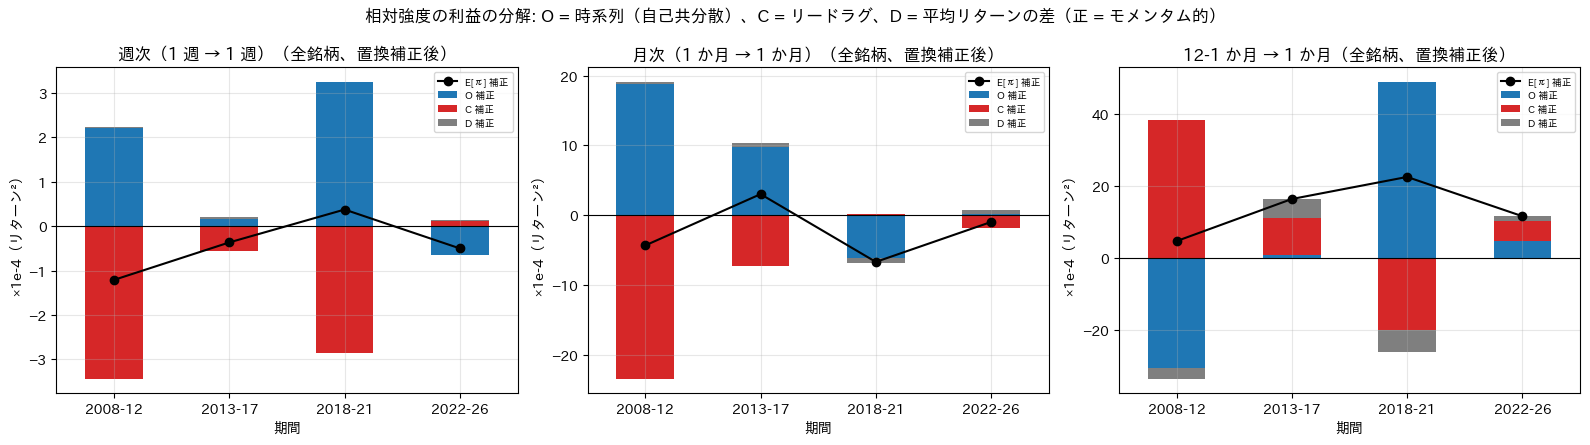

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, fname in zip(axes, FORMS):
    sub = lm_tbl.xs((fname, "全銘柄"), level=["形成", "区分"])
    sub[["O 補正", "C 補正", "D 補正"]].plot.bar(
        ax=ax, stacked=True, rot=0, color=["C0", "C3", "C7"]
    )
    ax.plot(range(len(sub)), sub["E[π] 補正"], "ko-", label="E[π] 補正")
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"{fname}（全銘柄、置換補正後）")
    ax.set_ylabel("×1e-4（リターン²）")
    ax.legend(fontsize=7)
plt.suptitle(
    "相対強度の利益の分解: O = 時系列（自己共分散）、C = リードラグ、D = 平均リターンの差（正 = モメンタム的）"
)
plt.tight_layout()
plt.show()

## 3. リードラグ

### 3.1 サイズ別ポートフォリオの交差自己相関

大型（時価総額加重 `cw_large`）、中型（等ウェイト `ew_mid`）、小型（等ウェイト `ew_small`）の日次・週次リターンで、
行 = 前期間、列 = 当期間の相関。対角が自己相関、右上（大型 → 小型）が左下より大きければ「大型が先行」。

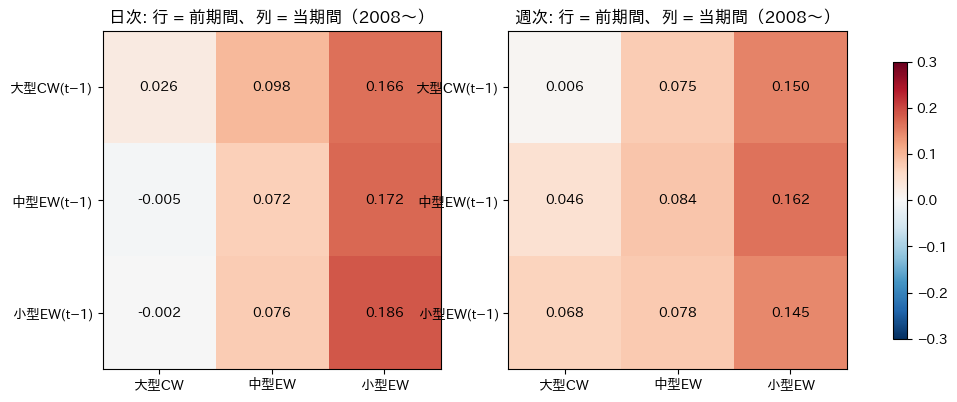

In [8]:
di = panel.daily_index.loc["2008":, ["cw_large", "ew_mid", "ew_small"]].rename(
    columns={"cw_large": "大型CW", "ew_mid": "中型EW", "ew_small": "小型EW"}
)
wi = np.expm1(np.log1p(di).resample("W-FRI").sum(min_count=1))


def cross_autocorr(df: pd.DataFrame) -> pd.DataFrame:
    lag = df.shift(1)
    return pd.DataFrame({c2: {c1: df[c2].corr(lag[c1]) for c1 in df} for c2 in df})


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (nm, df) in zip(axes, (("日次", di), ("週次", wi))):
    m = cross_autocorr(df)
    im = ax.imshow(m.to_numpy(), cmap="RdBu_r", vmin=-0.3, vmax=0.3)
    ax.set_xticks(range(3), m.columns)
    ax.set_yticks(range(3), [f"{c}(t−1)" for c in m.index])
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{m.iloc[i, j]:.3f}", ha="center", va="center")
    ax.set_title(f"{nm}: 行 = 前期間、列 = 当期間（2008〜）")
    ax.grid(False)
plt.colorbar(im, ax=axes, shrink=0.8)
plt.show()

### 3.2 大型の前期間リターンは小型を予測するか（自己ラグを制御）

$r^{S}_t = a + b_S\, r^{S}_{t-1} + b_L\, r^{L}_{t-1} + e_t$（小型 EW を大型 CW の前期間で回帰）。逆向き（小型 → 大型）も同じ形で。
$b_L > 0$ かつ $b_S$ を入れても残るなら、大型の情報が遅れて小型に織り込まれている。図は 2 年ローリングの $b_L$（日次）。

小型←小型 b     t1  小型←大型 b     t2  大型←小型 b     t3
頻度 期間                                                     
日次 2008-26    0.149  3.848    0.048  1.110   -0.062 -1.652
   2008-12    0.138  1.662    0.103  1.466   -0.176 -2.360
   2013-17    0.164  3.019    0.031  0.522   -0.016 -0.409
   2018-21    0.269  3.957   -0.137 -1.486    0.058  0.888
   2022-26    0.070  1.206    0.047  0.526    0.012  0.249
週次 2008-26    0.070  1.165    0.118  1.365    0.141  2.622
   2008-12    0.024  0.279    0.213  1.592    0.167  1.830
   2013-17   -0.026 -0.261    0.171  1.148    0.038  0.623
   2018-21    0.420  3.015   -0.206 -1.562    0.320  2.217
   2022-26   -0.088 -0.695    0.074  0.528   -0.011 -0.157

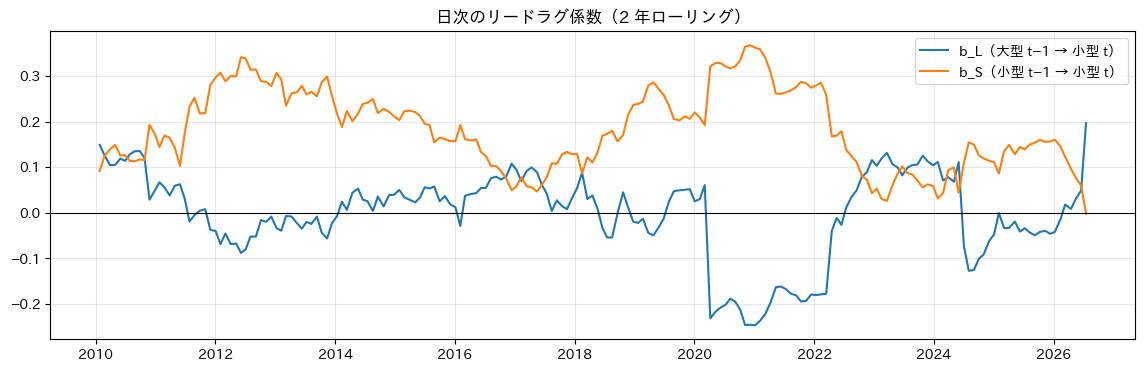

In [9]:
def ols_nw(y: pd.Series, X: pd.DataFrame, lags: int = 5) -> pd.DataFrame:
    d = pd.concat([y.rename("_y"), X], axis=1).dropna()
    A = np.column_stack([np.ones(len(d)), d[X.columns].to_numpy()])
    yv = d["_y"].to_numpy()
    b = np.linalg.lstsq(A, yv, rcond=None)[0]
    e = yv - A @ b
    n = len(d)
    Ainv = np.linalg.inv(A.T @ A)
    S = (A * e[:, None]).T @ (A * e[:, None]) / n
    for lag in range(1, lags + 1):
        G = (A[lag:] * e[lag:, None]).T @ (A[:-lag] * e[:-lag, None]) / n
        S += (1 - lag / (lags + 1)) * (G + G.T)
    V = n * Ainv @ S @ Ainv
    se = np.sqrt(np.diag(V))
    return pd.DataFrame({"coef": b, "t": b / se}, index=["const", *X.columns])


rows = []
for nm, df in (("日次", di), ("週次", wi)):
    for a, e in [("2008", "2026"), *SUBPERIODS]:
        sub = df.loc[a:e]
        lag = sub.shift(1)
        r1 = ols_nw(
            sub["小型EW"],
            lag[["小型EW", "大型CW"]].rename(columns=lambda c: c + "(t−1)"),
        )
        r2 = ols_nw(
            sub["大型CW"],
            lag[["大型CW", "小型EW"]].rename(columns=lambda c: c + "(t−1)"),
        )
        rows.append(
            {
                "頻度": nm,
                "期間": f"{a}-{e[2:]}",
                "小型←小型 b": r1.loc["小型EW(t−1)", "coef"],
                "t1": r1.loc["小型EW(t−1)", "t"],
                "小型←大型 b": r1.loc["大型CW(t−1)", "coef"],
                "t2": r1.loc["大型CW(t−1)", "t"],
                "大型←小型 b": r2.loc["小型EW(t−1)", "coef"],
                "t3": r2.loc["小型EW(t−1)", "t"],
            }
        )
ll_tbl = pd.DataFrame(rows).set_index(["頻度", "期間"])
display(ll_tbl.round(3))

# 2 年ローリング（日次、504 営業日）の b_L
roll = []
idx = di.index
for end in range(504, len(idx), 21):
    sub = di.iloc[end - 504 : end]
    lag = sub.shift(1)
    r = ols_nw(sub["小型EW"], lag[["小型EW", "大型CW"]], lags=5)
    roll.append(
        (
            idx[end - 1],
            r.loc["大型CW", "coef"],
            r.loc["大型CW", "t"],
            r.loc["小型EW", "coef"],
        )
    )
roll = pd.DataFrame(roll, columns=["date", "b_L", "t_L", "b_S"]).set_index("date")
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(roll.index, roll["b_L"], label="b_L（大型 t−1 → 小型 t）")
ax.plot(roll.index, roll["b_S"], label="b_S（小型 t−1 → 小型 t）")
ax.axhline(0, color="k", linewidth=0.8)
ax.set_title("日次のリードラグ係数（2 年ローリング）")
ax.legend()
plt.show()

### 3.3 業種 → 銘柄の先行（週次・月次の FM）

銘柄の翌期間リターンを、自分の当期間リターンと所属セクター（GICS 11 区分）の当期間リターンで同時に回帰する FM。
セクターリターンは同じセクターの構成銘柄から**自分を除いた等ウェイト平均**（大型株で自分のリターンが混ざるのを避ける）。
セクター係数が正なら「業種のリターンに銘柄が遅れて追いつく」（Hou 2007 の業種内リードラグ）。
既存 `industry_factor/02` の `ITREND_SREV`（業種で順張り × 銘柄で逆張り、月次）と同じ現象の週次・サイズ別の確認になる。

In [10]:
def sector_ex_self(
    r: pd.DataFrame, sector: pd.DataFrame, mask: pd.DataFrame
) -> pd.DataFrame:
    # 同じセクターの構成銘柄（自分を除く）の等ウェイト平均リターン
    out = pd.DataFrame(np.nan, index=r.index, columns=r.columns)
    rr = r.where(mask)
    for code in SECTOR_NAMES:
        m = (sector == code) & mask & rr.notna()
        tot, n = rr.where(m).sum(axis=1), m.sum(axis=1)
        ex = (rr.where(m).rsub(tot, axis=0)).div(n - 1, axis=0)
        out = out.mask(m & (n > 2).to_numpy()[:, None], ex)
    return out


def sector_fm(r_now, y, sector, univ_mask, size, lags, is_end, end=None):
    rows = []
    sec_ex = sector_ex_self(r_now, sector, univ_mask)
    for seg, mask in (
        ("全銘柄", univ_mask),
        *[(nm, univ_mask & (size == k)) for k, nm in SIZE_NAMES.items()],
    ):
        zs = {"own": zrank(r_now, mask), "sector": zrank(sec_ex, mask)}
        co = fm_multi(zs, y, min_n=15)
        rec = {"区分": seg}
        for k in zs:
            rec[f"{k} bp"] = co[k].mean() * 1e4
            rec[f"{k} t"] = nw_t(co[k], lags)
            rec[f"{k} t IS"] = nw_t(co[k].loc[:is_end], lags)
            rec[f"{k} t OOS"] = nw_t(co[k].loc[is_end:].iloc[1:], lags)
        rows.append(rec)
    return pd.DataFrame(rows).set_index("区分"), co


wk = wret.loc["2008":"2026-07-24"].index
ind_w, co_w_small = sector_fm(
    wret.loc[wk],
    wret.shift(-1).loc[wk],
    sector_w.loc[wk],
    mem_w.loc[wk],
    size_w.loc[wk],
    5,
    "2017-12-29",
)
sector_mm = on_months(panel.monthly["sector"])
ind_m, _ = sector_fm(
    on_months(mret), FWD["drtn"], sector_mm, U, SIZE, 3, IS_LAST_SIGNAL
)
ind_tbl = pd.concat({"週次": ind_w, "月次": ind_m}, names=["頻度"])
display(ind_tbl.round(2))

own bp  own t  own t IS  own t OOS  sector bp  sector t  sector t IS  sector t OOS
頻度 区分                                                                                       
週次 全銘柄     -8.35  -3.40     -2.34      -2.68      10.69      6.79         4.14          5.65
   large  -18.03  -5.62     -5.80      -2.02       7.23      2.87         1.76          2.37
   mid    -15.30  -3.78     -3.04      -2.26      10.00      2.68         2.53          1.05
   small   -5.13  -2.00     -0.99      -2.28      11.94      7.26         4.57          5.84
月次 全銘柄    -10.58  -1.20      0.07      -2.23      36.32      4.43         4.69          1.88
   large  -22.36  -1.80     -1.46      -1.07      27.32      2.23         2.21          0.78
   mid    -41.49  -2.74     -1.38      -2.87      24.62      1.59         2.15         -0.04
   small   -3.80  -0.41      0.57      -1.50      39.07      4.55         4.69          2.07

## 4. 価格遅延（Hou–Moskowitz D1）

各月末 $t$ に、直近 52 週の週次リターンを市場（`cw_imi`）の当週とラグ 1〜4 週で回帰し、
$D1 = 1 - R^2_{\text{当週のみ}} / R^2_{\text{ラグ込み}}$ を計算する（40 週以上の値がある銘柄）。
D1 が大きいほど、市場の情報を遅れて織り込む銘柄。

D1 の平均: 0.267  中央値: 0.199


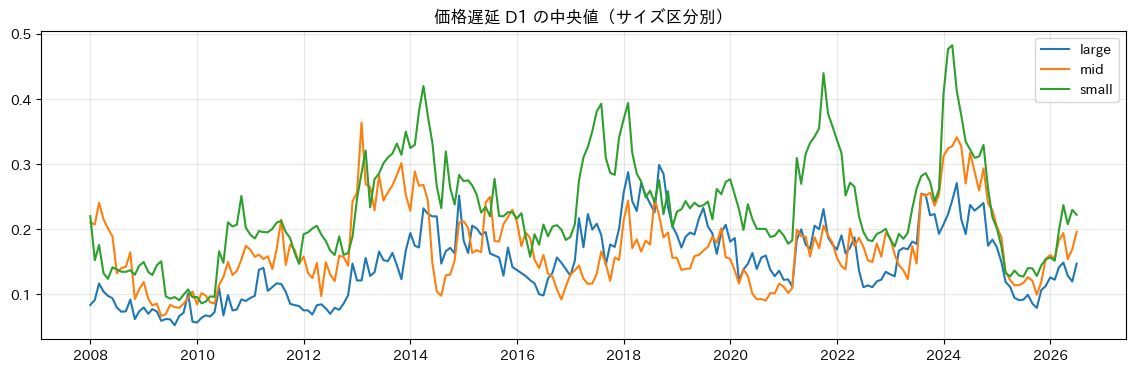

In [11]:
mkt_w = np.expm1(
    np.log1p(panel.daily_index["cw_imi"]).resample("W-FRI").sum(min_count=1)
)
mlags = pd.concat({k: mkt_w.shift(k) for k in range(5)}, axis=1)
W = wret.reindex(columns=COLS)


def r2(A: np.ndarray, y: np.ndarray) -> float:
    b = np.linalg.lstsq(A, y, rcond=None)[0]
    e = y - A @ b
    yc = y - y.mean()
    return 1 - (e @ e) / (yc @ yc)


d1_rows = {}
for t in months:
    win = W.loc[:t].iloc[-52:]
    X = mlags.reindex(win.index).to_numpy(float)
    if np.isnan(X).any() or len(win) < 52:
        continue
    cols = U.columns[U.loc[t].to_numpy()]
    Y = win[cols].to_numpy(float)
    ok_n = np.isfinite(Y).sum(axis=0)
    full = np.column_stack([np.ones(52), X])
    rest = full[:, :2]
    vals = {}
    complete = ok_n == 52
    if complete.any():  # 全週ある銘柄はまとめて計算
        Yc = Y[:, complete]

        def r2_mat(A):
            B = np.linalg.lstsq(A, Yc, rcond=None)[0]
            E = Yc - A @ B
            C = Yc - Yc.mean(axis=0)
            return 1 - (E**2).sum(axis=0) / (C**2).sum(axis=0)

        rf, rr = r2_mat(full), r2_mat(rest)
        vals.update(dict(zip(cols[complete], 1 - rr / rf)))
    for j in np.where((ok_n >= 40) & ~complete)[0]:
        m = np.isfinite(Y[:, j])
        rf, rr = r2(full[m], Y[m, j]), r2(rest[m], Y[m, j])
        vals[cols[j]] = 1 - rr / rf
    d1_rows[t] = pd.Series(vals)
D1 = pd.DataFrame(d1_rows).T.reindex(index=months, columns=COLS)
SIG["D1（価格遅延）"] = D1
print(
    "D1 の平均:", round(D1.stack().mean(), 3), " 中央値:", round(D1.stack().median(), 3)
)

fig, ax = plt.subplots(figsize=(14, 4))
for k, nm in SIZE_NAMES.items():
    ax.plot(D1.where(SIZE == k).median(axis=1), label=nm)
ax.set_title("価格遅延 D1 の中央値（サイズ区分別）")
ax.legend()
plt.show()

D1 と各特性の順位相関（月平均）


,mom1,mom12_1,tover,vola60,skew60,logcap
corr,0.015,0.09,-0.103,-0.047,0.021,-0.137


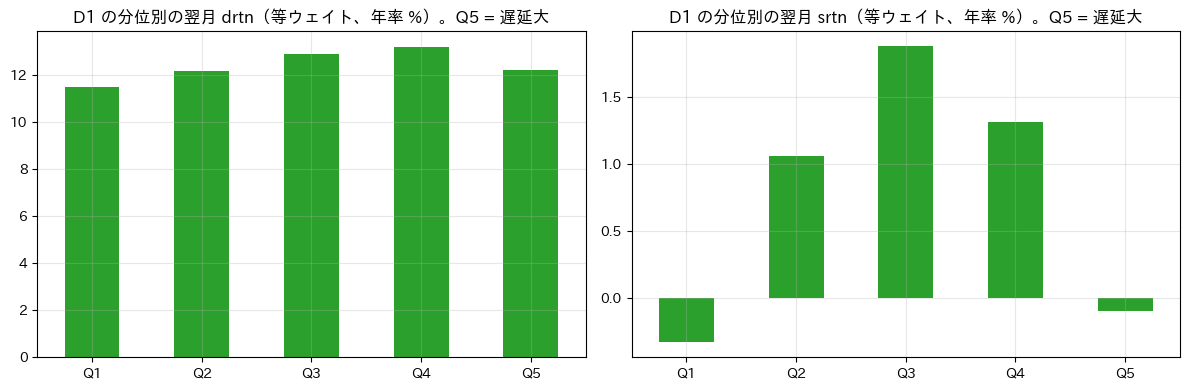

In [12]:
logcap = np.log(on_months(cap_m))
to_m = panel.daily["turnover"].resample("M").mean()
ctrl_raw = {
    "mom1": store.alpha("core/mom1", 200712, 202606),
    "mom12_1": store.alpha("core/mom12_1", 200712, 202606),
    "tover": store.alpha("core/tover", 200712, 202606),
    "vola60": store.alpha("core/vola60", 200712, 202606),
    "skew60": store.alpha("core/skew60", 200712, 202606),
}
CTRL = {k: on_months(v) for k, v in ctrl_raw.items()}
CTRL["logcap"] = logcap
CTRL_Z = {k: zrank(v, U) for k, v in CTRL.items()}

zD1 = zrank(D1, U)
print("D1 と各特性の順位相関（月平均）")
display(
    pd.Series({k: zD1.T.corrwith(v.T).mean() for k, v in CTRL_Z.items()})
    .round(3)
    .to_frame("corr")
    .T
)


# D1 の 5 分位（ユニバース内）の翌月リターン（等ウェイト、drtn・srtn）
def quintile_means(z: pd.DataFrame, y: pd.DataFrame, n: int = 5) -> pd.Series:
    valid = z.notna() & y.notna()
    p = z.where(valid).rank(axis=1).sub(0.5).div(valid.sum(axis=1), axis=0)
    q = np.floor(p * n).clip(0, n - 1) + 1
    return pd.Series(
        {f"Q{k}": y.where(q == k).mean(axis=1).mean() * 1200 for k in range(1, n + 1)}
    )


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, rk in zip(axes, ("drtn", "srtn")):
    quintile_means(zD1, FWD[rk]).plot.bar(ax=ax, rot=0, color="C2")
    ax.set_title(f"D1 の分位別の翌月 {rk}（等ウェイト、年率 %）。Q5 = 遅延大")
plt.tight_layout()
plt.show()

## 5. オーバーナイトと日中（綱引き）

月 $t$ のオーバーナイトリターン（前日終値 → 始値）の累計 `ON` と日中（始値 → 終値）の累計 `ID` を別々の特性にする（10 日以上の値がある銘柄）。
インドでは 9:00〜9:08 のプレオープン・コールオークションで始値が決まるので、オーバーナイトはオークション価格までの変化。

注意: 構成銘柄の日次オーバーナイトリターンのうち 3〜10% はちょうど 0（始値 = 前日終値。近年ほど多い）で、
プレオープンで約定しなかった銘柄の始値の扱いの可能性がある。

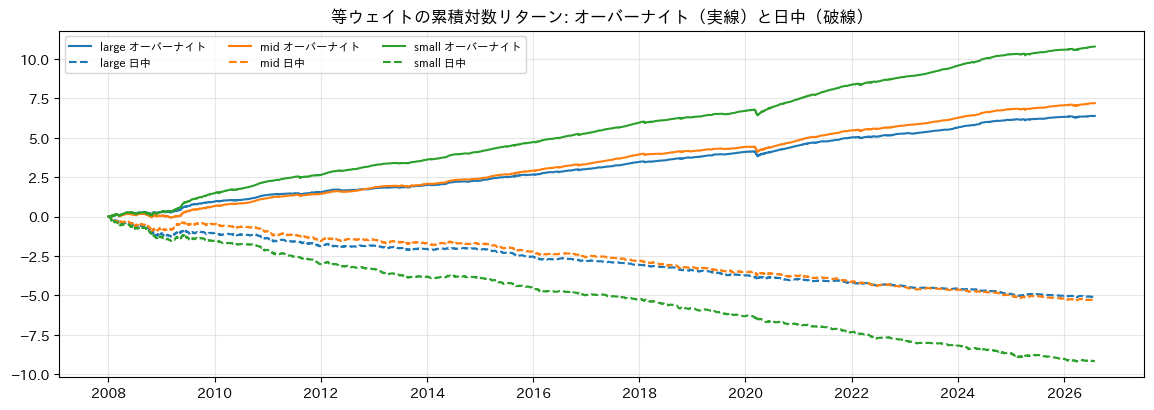

,ON %,ON t,ON t IS,ON t OOS,ID %,ID t,ID t IS,ID t OOS
被説明変数,,,,,,,,
drtn,0.038,0.443,0.676,-0.173,-0.138,-1.389,-0.338,-2.001
srtn,-0.036,-0.447,-0.466,-0.107,-0.280,-3.503,-2.158,-2.961
翌月 ON,1.277,16.005,13.364,13.423,-0.763,-7.073,-5.629,-5.062
翌月 ID,-1.212,-11.194,-8.525,-9.824,0.627,4.947,4.686,2.439


In [13]:
on_m = np.expm1(np.log1p(panel.daily["ret_on"]).resample("M").sum(min_count=10))
id_m = np.expm1(np.log1p(panel.daily["ret_id"]).resample("M").sum(min_count=10))
ON, ID = on_months(on_m), on_months(id_m)
SIG["ON（オーバーナイト）"] = on_m
SIG["ID（日中）"] = id_m

# 等ウェイトのユニバース平均の累積（サイズ別）
on_d, id_d = panel.daily["ret_on"].loc["2008":], panel.daily["ret_id"].loc["2008":]
fig, ax = plt.subplots(figsize=(14, 4.5))
for k, nm in SIZE_NAMES.items():
    m = mem_d8 & (size_d8 == k)
    ax.plot(
        np.log1p(on_d.where(m).mean(axis=1)).cumsum(),
        label=f"{nm} オーバーナイト",
        color=f"C{k - 1}",
    )
    ax.plot(
        np.log1p(id_d.where(m).mean(axis=1)).cumsum(),
        label=f"{nm} 日中",
        color=f"C{k - 1}",
        linestyle="--",
    )
ax.set_title("等ウェイトの累積対数リターン: オーバーナイト（実線）と日中（破線）")
ax.legend(ncol=3, fontsize=8)
plt.show()

# 予測: 翌月の総リターン / オーバーナイト / 日中
targets = {
    "drtn": FWD["drtn"],
    "srtn": FWD["srtn"],
    "翌月 ON": on_months(on_m.shift(-1)),
    "翌月 ID": on_months(id_m.shift(-1)),
}
rows = []
for tname, y in targets.items():
    co = fm_multi({"ON": zrank(ON, U), "ID": zrank(ID, U)}, y)
    rec = {"被説明変数": tname}
    for k in ("ON", "ID"):
        rec[f"{k} %"] = co[k].mean() * 100
        rec[f"{k} t"] = nw_t(co[k])
        rec[f"{k} t IS"] = nw_t(co[k][IS])
        rec[f"{k} t OOS"] = nw_t(co[k][~IS])
    rows.append(rec)
display(pd.DataFrame(rows).set_index("被説明変数").round(3))

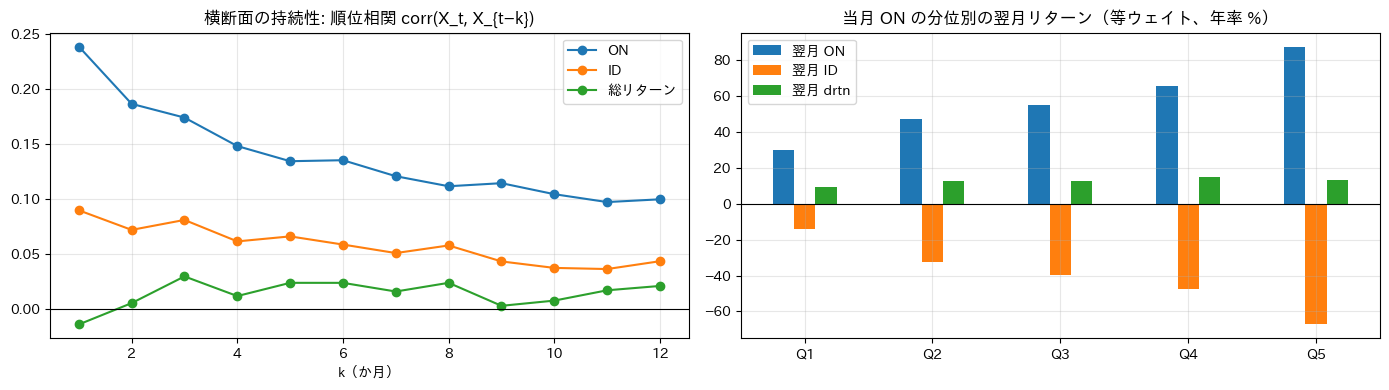

,1,2,3,4,5,6,7,8,9,10,11,12
ON,0.239,0.187,0.174,0.148,0.134,0.135,0.121,0.112,0.115,0.105,0.097,0.100
ID,0.090,0.072,0.081,0.062,0.066,0.059,0.051,0.058,0.044,0.038,0.037,0.044
総リターン,-0.014,0.006,0.030,0.012,0.024,0.024,0.016,0.024,0.003,0.008,0.017,0.021


In [14]:
# 持続性: 横断面の順位相関 corr(X_t, X_{t-k})
zON, zID, zR = (
    zrank(on_months(on_m), U),
    zrank(on_months(id_m), U),
    zrank(on_months(mret), U),
)
pers = {}
for k in range(1, 13):
    pers[k] = {
        nm: z.T.corrwith(zrank(on_months(src.shift(k)), U).T).mean()
        for nm, z, src in (
            ("ON", zON, on_m),
            ("ID", zID, id_m),
            ("総リターン", zR, mret),
        )
    }
pers = pd.DataFrame(pers).T

# 綱引き: ON の 5 分位別の翌月 ON / ID（年率 %）
tug = pd.DataFrame(
    {
        tn: quintile_means(zON, y)
        for tn, y in (
            ("翌月 ON", targets["翌月 ON"]),
            ("翌月 ID", targets["翌月 ID"]),
            ("翌月 drtn", FWD["drtn"]),
        )
    }
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pers.plot(ax=axes[0], marker="o")
axes[0].axhline(0, color="k", linewidth=0.8)
axes[0].set_title("横断面の持続性: 順位相関 corr(X_t, X_{t−k})")
axes[0].set_xlabel("k（か月）")
tug.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("当月 ON の分位別の翌月リターン（等ウェイト、年率 %）")
axes[1].axhline(0, color="k", linewidth=0.8)
plt.tight_layout()
plt.show()
display(pers.round(3).T)

## 6. 出来高・極端値

- `abn_to`: 異常回転率 = log（月 $t$ の平均日次回転率 / 前 12 か月の月平均回転率の平均）。高出来高プレミアムなら正。
- `MAX`: 月 $t$ の最大日次リターン（宝くじ性）。負が予測。
- `hi52`: 月末終値 / 過去 252 営業日の最高値（52 週高値への近さ）。正が予測。

さらに、直近 1 か月リターンと異常回転率の 3 × 3 の二重ソート（独立）で、「出来高を伴う上昇は続き、伴わない上昇は反転するか」を見る。

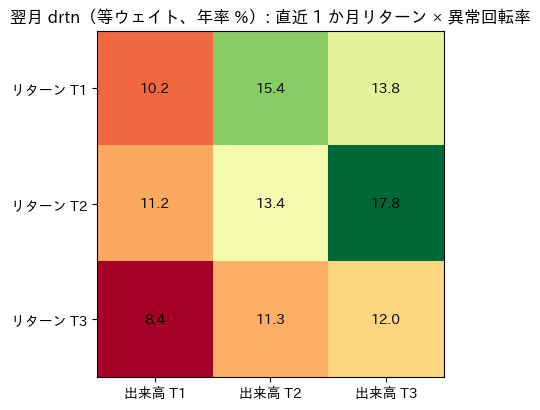

出来高ターシャイル別の、リターン T3 − T1（翌月 drtn、負 = リバーサル）


,出来高 T1,出来高 T2,出来高 T3
T3−T1 年%,-1.81,-4.05,-1.80
t,-0.59,-1.37,-0.53


,ret1,abn_to,ret1×abn_to,tover,logcap,vola60
%/月,-0.117,0.157,0.016,-0.024,-0.072,-0.229
t,-1.571,2.721,0.287,-0.276,-0.902,-1.672
t IS,-0.234,2.676,0.088,-0.598,-1.604,-1.920
t OOS,-2.275,1.111,0.400,0.295,0.488,-0.155


In [15]:
to_ratio = to_m / to_m.shift(1).rolling(12, min_periods=6).mean()
abn_to = np.log(to_ratio.where(to_ratio > 0))
max1 = ret_d.resample("M").max()
close = panel.daily["close"]
hi52 = (
    (close.ffill(limit=5) / close.rolling(252, min_periods=200).max())
    .resample("M")
    .last()
)
SIG["abn_to（異常回転率）"] = abn_to
SIG["MAX（月内最大日次）"] = max1
SIG["hi52（52 週高値比）"] = hi52

# 二重ソート: 直近 1 か月リターン × 異常回転率（ターシャイル、独立）
zr, za = zrank(on_months(mret), U), zrank(on_months(abn_to), U)
valid = zr.notna() & za.notna() & FWD["drtn"].notna()


def terc(z: pd.DataFrame) -> pd.DataFrame:
    p = z.where(valid).rank(axis=1).sub(0.5).div(valid.sum(axis=1), axis=0)
    return np.floor(p * 3).clip(0, 2) + 1


tr, ta = terc(zr), terc(za)
grid = pd.DataFrame(
    {
        f"出来高 T{j}": {
            f"リターン T{i}": FWD["drtn"]
            .where((tr == i) & (ta == j))
            .mean(axis=1)
            .mean()
            * 1200
            for i in (1, 2, 3)
        }
        for j in (1, 2, 3)
    }
)
spread_by_vol = {}
for j in (1, 2, 3):
    s = FWD["drtn"].where((tr == 3) & (ta == j)).mean(axis=1) - FWD["drtn"].where(
        (tr == 1) & (ta == j)
    ).mean(axis=1)
    spread_by_vol[f"出来高 T{j}"] = {"T3−T1 年%": s.mean() * 1200, "t": nw_t(s)}
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(grid.to_numpy(), cmap="RdYlGn")
ax.set_xticks(range(3), grid.columns)
ax.set_yticks(range(3), grid.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{grid.iloc[i, j]:.1f}", ha="center", va="center")
ax.set_title("翌月 drtn（等ウェイト、年率 %）: 直近 1 か月リターン × 異常回転率")
ax.grid(False)
plt.show()
print("出来高ターシャイル別の、リターン T3 − T1（翌月 drtn、負 = リバーサル）")
display(pd.DataFrame(spread_by_vol).round(2))

# 交差項の FM
zint = zrank(on_months(mret), U) * zrank(on_months(abn_to), U)
co = fm_multi(
    {
        "ret1": zr,
        "abn_to": za,
        "ret1×abn_to": zint,
        **{k: CTRL_Z[k] for k in ("tover", "logcap", "vola60")},
    },
    FWD["drtn"],
)
display(
    pd.DataFrame(
        {
            "%/月": co.mean() * 100,
            "t": co.apply(nw_t),
            "t IS": co[IS].apply(nw_t),
            "t OOS": co[~IS].apply(nw_t),
        }
    )
    .round(3)
    .T
)

## 7. 候補特性のまとめ

### 7.1 単独の成績

全候補を同じ形式で評価する（FM の係数と t 値、IS / OOS、等ウェイト Q5−Q1、サイズ区分別の t 値）。
符号は素の値の向き（例: `MAX` が負なら「最大日次リターンが大きい銘柄ほど翌月が悪い」）。

In [16]:
res = pd.DataFrame([evaluate(v, k) for k, v in SIG.items()])
display(res.round(2))

,drtn FM%,drtn t,IS t,OOS t,drtn Q5−Q1 年%,drtn Q t,srtn FM%,srtn t,srtn Q5−Q1 年%,srtn Q t,large t,mid t,small t
rev1（直近 1 か月）,-0.08,-0.88,0.37,-2.05,-2.30,-0.76,-0.21,-2.99,-6.20,-2.54,-1.30,-2.45,-0.24
seas（同月の過去平均）,0.09,1.09,0.30,1.33,3.20,1.08,0.10,1.50,3.42,1.47,0.95,0.72,0.75
D1（価格遅延）,0.03,0.31,0.11,0.48,0.70,0.24,0.01,0.14,0.24,0.11,-0.49,0.89,-0.07
ON（オーバーナイト）,0.13,1.86,1.74,0.93,3.84,1.65,0.11,1.84,3.04,1.44,-0.52,-1.62,2.29
ID（日中）,-0.13,-1.59,-0.43,-1.95,-3.61,-1.34,-0.23,-3.59,-6.97,-3.18,-0.41,-1.59,-1.21
abn_to（異常回転率）,0.17,2.70,2.80,0.75,4.72,2.15,0.15,2.74,3.85,1.96,1.53,0.13,2.48
MAX（月内最大日次）,-0.05,-0.60,0.01,-1.12,-1.20,-0.38,-0.06,-1.09,-1.70,-0.88,0.24,-1.51,-1.04
hi52（52 週高値比）,0.19,1.08,0.41,1.63,5.57,0.97,0.06,0.62,0.64,0.21,-0.87,0.21,1.76


### 7.2 既存特性との相関と、同時に入れた FM での残存

`core` の mom1・mom12_1・tover・vola60・skew60 と log 時価総額を同時に入れた FM（drtn と srtn）での候補の係数。

In [17]:
corr_rows, ctl_rows = {}, {}
for k, v in SIG.items():
    z = zrank(on_months(v), U)
    corr_rows[k] = {c: z.T.corrwith(cz.T).mean() for c, cz in CTRL_Z.items()}
    rec = {}
    ctrls = {
        c: cz for c, cz in CTRL_Z.items() if abs(corr_rows[k][c]) < 0.95
    }  # rev1 と mom1 は同一なので外す
    rec["除いた制御"] = ",".join(c for c in CTRL_Z if c not in ctrls)
    for rk in ("drtn", "srtn"):
        co = fm_multi({"sig": z, **ctrls}, FWD[rk])
        rec[f"{rk} %"] = co["sig"].mean() * 100
        rec[f"{rk} t"] = nw_t(co["sig"])
        if rk == "drtn":
            rec["IS t"] = nw_t(co["sig"][IS])
            rec["OOS t"] = nw_t(co["sig"][~IS])
    ctl_rows[k] = rec
print("候補と既存特性の順位相関（月平均）")
display(pd.DataFrame(corr_rows).T.round(2))
print(
    "既存特性（mom1, mom12_1, tover, vola60, skew60, logcap）を同時に入れた FM での候補の係数"
)
ctl_tbl = pd.DataFrame(ctl_rows).T
display(ctl_tbl.round(3))

候補と既存特性の順位相関（月平均）


,mom1,mom12_1,tover,vola60,skew60,logcap
rev1（直近 1 か月）,1.00,0.04,0.05,-0.05,-0.03,0.11
seas（同月の過去平均）,0.00,0.12,0.00,0.08,0.03,0.01
D1（価格遅延）,0.02,0.09,-0.10,-0.05,0.02,-0.14
ON（オーバーナイト）,0.10,-0.02,0.16,0.14,0.06,-0.16
ID（日中）,0.82,0.05,-0.03,-0.10,-0.05,0.18
abn_to（異常回転率）,0.23,-0.04,0.31,-0.05,-0.06,0.13
MAX（月内最大日次）,0.37,-0.00,0.40,0.33,0.09,-0.15
hi52（52 週高値比）,0.47,0.58,-0.24,-0.34,-0.11,0.33


既存特性（mom1, mom12_1, tover, vola60, skew60, logcap）を同時に入れた FM での候補の係数


,除いた制御,drtn %,drtn t,IS t,OOS t,srtn %,srtn t
rev1（直近 1 か月）,mom1,-0.156849,-1.972005,-0.422443,-3.027297,-0.193245,-2.58667
seas（同月の過去平均）,,0.076546,1.237539,0.247248,1.449302,0.096143,1.696492
D1（価格遅延）,,-0.034877,-0.475571,-0.752397,0.416622,-0.020615,-0.373868
ON（オーバーナイト）,,0.125439,1.981218,2.331075,0.437554,0.136736,2.265987
ID（日中）,,-0.266383,-2.312412,-3.163877,-0.343981,-0.272563,-2.596687
abn_to（異常回転率）,,0.178066,3.251354,2.536189,2.041853,0.19906,3.657306
MAX（月内最大日次）,,-0.066873,-1.191567,-0.121593,-2.174638,-0.006579,-0.12908
hi52（52 週高値比）,,0.134999,0.981647,-0.055705,1.923185,0.023818,0.186302


### 7.3 累積 Q5−Q1

向きは文献の予測（事前に決めたもの）にそろえた: `rev1`・`ID`・`MAX` は反転（−1 倍）、他はそのまま。等ウェイト、翌月 drtn。

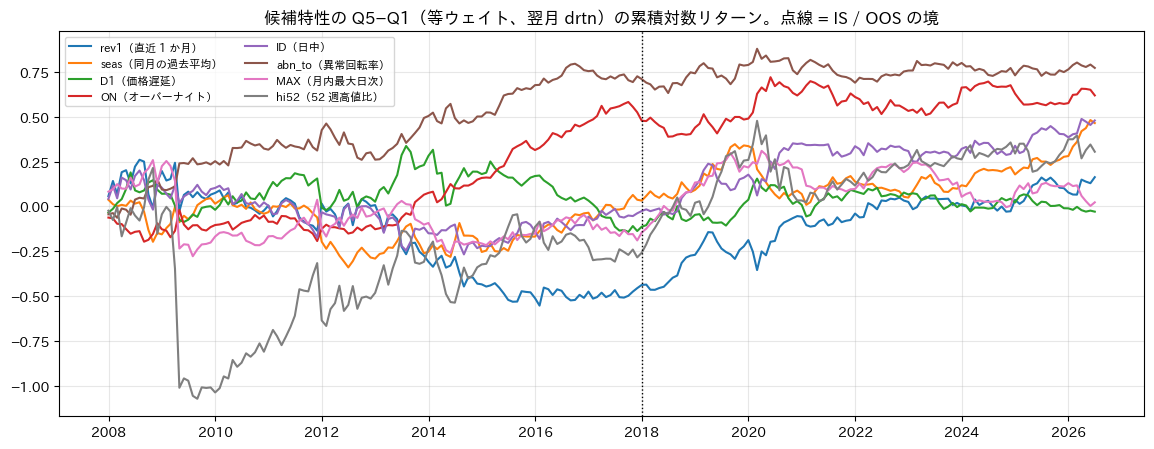

In [18]:
ORIENT = {"rev1（直近 1 か月）": -1, "ID（日中）": -1, "MAX（月内最大日次）": -1}
fig, ax = plt.subplots(figsize=(14, 5))
for i, (k, v) in enumerate(SIG.items()):
    z = zrank(on_months(v) * ORIENT.get(k, 1), U)
    sp = q_spread(z, FWD["drtn"])
    ax.plot(np.log1p(sp.fillna(0)).cumsum(), label=k, color=f"C{i}")
ax.axvline(pd.Timestamp("2017-12-31"), color="k", linestyle=":", linewidth=1)
ax.set_title(
    "候補特性の Q5−Q1（等ウェイト、翌月 drtn）の累積対数リターン。点線 = IS / OOS の境"
)
ax.legend(fontsize=8, ncol=2)
plt.show()

## 所見

**結論: 時系列由来の特性で頑健に残ったのは「業種（自分を除く等ウェイト）の前週リターンへの追随」（週次 FM t 6.8、IS 4.1 / OOS 5.7）と「異常回転率」（既存特性を制御して t 3.3、IS 2.5 / OOS 2.0）の 2 つ。オーバーナイト / 日中の綱引きは非常に強いが総リターンでは打ち消し合い、アルファより執行タイミングの情報。価格遅延・MAX・52 週高値・季節性は効かない。12-1 か月モメンタムの利益は、小標本バイアスを補正すると「平均リターンの差」ではなく銘柄固有の系列の予測可能性から来ていて、小型株に集中する。**

1. **ラグ構造（§1.1〜1.2）**: 月次ラグ単独の FM で |t| > 2 は srtn のラグ 1（−3.0）・6（2.2）・12（2.2）だけ。年周期ラグ（12・24・36）の平均 t は 0.99、非年周期は 0.21 で、
   Heston–Sadka の季節性の方向は出るが弱い。同月の過去平均 `seas` は drtn t 1.1（IS 0.3 / OOS 1.3）、既存特性を制御して 1.2。候補にしない。
2. **短期の自己相関はサイズで逆向き（§1.3）**: 日次では前日リターン 1σ あたり当日 +3.0bp（t 6.6）の**続伸**で、小型株が担う（+3.6bp、t 7.2）。
   週次では −8.0bp（t −3.2）の**反転**で、大型株が最も強い（−16.7bp、t −5.0。小型は −5.2bp、t −2.0）。
   小型株の日次の続伸は値幅制限（サーキット）と非同時取引による価格調整の遅れと整合し、小型 EW 指数の日次自己相関も 0.15（t 3.8）。
   日次リターンから推定した小型株のボラ・ベータは偏りやすい（週次で推定するか Dimson 補正が要る）。
3. **Lo–MacKinlay の分解（§2、ブートストラップで小標本バイアスを補正）**:
   - **12-1 か月 → 1 か月**: 補正後の期待利益は 4 期間すべて正（全銘柄 4.6 / 16.3 / 22.4 / 11.5 ×1e-4）。中身は O+C（銘柄固有の系列の予測可能性: 7.5 / 11.1 / 28.5 / 10.1、
     p = 0.33 / 0.09 / 0.04 / 0.06）で、平均の差 D は補正後 −6〜+5 と小さい。補正前は O が −80（2008〜12 年）、D が 21〜29 で「時系列リバーサル + 平均の差」に見えるが、
     これは 11 か月の重なりによるバイアス。**大型 + 中型では補正後の利益が 4 期間ともほぼ 0 か負**（−13.8 / −2.4 / −5.2 / −0.4）、小型は 10.6 / 22.0 / 30.6 / 16.3 で、
     インドの相対強度モメンタムは小型株の現象。
   - **月次 1 → 1**: 補正後 −4.3 / +3.0 / −6.7 / −0.9 で、2008〜12 年と 2018〜21 年に反転、方向は安定しない。
   - **週次 1 → 1**: 3 期間で逆張りの利益（E[π] 補正 −1.2 / −0.4 / +0.4 / −0.5）。会計上は C（リードラグ）が −3.4 と大きく、O は +2.2 で逆向き。
     ただし C はほぼ市場の自己共分散 γ_m（3.3）の裏返しで、O + C（p ≈ 1.0、有意に負）として読むのが正しい: **銘柄の相対リターンが翌週に反転する**。
   - O と C は全形成期間で鏡像（γ_m が両方に入る）。インドでは市場レベルの自己相関（2008〜12 年の 12-1 か月で γ_m = −63、週次で正）が大きく、
     分解の各項は市場成分を除いて読む必要がある。
4. **サイズ間のリードラグ（§3.1〜3.2）**: 大型 → 小型の先行は弱い（日次 b = 0.048、t 1.1。週次 0.118、t 1.4）。2018〜21 年は符号が逆。米国の古典的な結果（大型が小型を先行）はインドでは確認できない。
   小型株の予測可能性はもっぱら自己ラグ（日次 0.149、t 3.8）。
5. **業種 → 銘柄の先行（§3.3、本ノートで最も頑健）**: 自分の前週リターンと同時に入れても、同じセクターの他銘柄（等ウェイト）の前週リターン 1σ あたり翌週 +10.7bp（t 6.8、IS 4.1 / OOS 5.7）。
   小型 +11.9bp（t 7.3、OOS 5.8）、大型 +7.2bp（t 2.9）、中型 +10.0bp（t 2.7、OOS 1.1）。同時に自分の前週リターンは −8.4bp（t −3.4）で、
   **「業種で順張り × 銘柄で逆張り」が週次でもはっきり出る**。月次では業種 +36bp（t 4.4）だが OOS は t 1.9 に弱まり、
   `industry_factor/02` の「`IMOM1` は OOS で弱まった」と整合する。週次の方が OOS で崩れていない。
6. **価格遅延 D1（§4）**: D1 の中央値 0.20、小型ほど高い（log 時価総額と −0.14）。翌月プレミアムは無い（drtn t 0.3、srtn t 0.1、分位も単調でない）。Hou–Moskowitz の結果は再現しない。
7. **オーバーナイト / 日中（§5）**: 綱引きは非常に強い。当月 ON 1σ あたり翌月 ON +1.28%（t 16.0）、翌月日中 −1.21%（t −11.2）、IS / OOS とも |t| > 8。
   ON の横断面の持続性は 1 か月で 0.24、12 か月でも 0.10（総リターンはほぼ 0）で、銘柄の「性格」に近い。ただし両者が打ち消して翌月の総リターンへの効果は 0（t 0.4）。
   日中 `ID` は mom1 と 0.82 の相関で、短期リバーサルの大半は日中側（srtn t −3.5）。既存特性を制御すると ON t 2.0、ID t −2.3 だが、どちらも OOS では t 0.4 / −0.3 に落ちる。
   等ウェイトの累積では、オーバーナイトが全サイズで右肩上がり、日中は横ばい〜右肩下がり（図）。
8. **出来高・極端値（§6）**: 異常回転率 `abn_to` は drtn t 2.7（IS 2.8 / OOS 0.8）、Q5−Q1 4.7%/年（t 2.2）、srtn t 2.7。mom1・mom12_1・tover・vola60・skew60・log 時価総額を
   同時に入れると t 3.3（IS 2.5 / OOS 2.0、srtn t 3.7）で、むしろ強まる。大型（t 1.5）と小型（t 2.5）で正。過去リターンとの交差は無い（交差項 t 0.3、二重ソートでも出来高別の反転の差は無い）。
   MAX は t −0.6（OOS で −1.1）、52 週高値比は t 1.1（mom12_1 と 0.58、mom1 と 0.47 の相関で、制御すると 1.0）。
9. 多重検定: 本ノートで見た特性は約 10 本、ラグは 36 本。|t| ≥ 3 かつ IS・OOS で同符号は、業種の週次追随と `abn_to`（制御後）だけ。

**含意**

- インドのモメンタムは「小型株の、市場を除いた系列の予測可能性」。大型 + 中型では相対強度の利益がほぼ無い。モメンタムのスリーブはサイズ区分ごとに効き方が違うので、
  区分内で標準化するか、小型で強く効く前提でウェイトを考える。
- 短期の時間軸では、**業種は続伸、銘柄は反転**が日次以外のすべての頻度で出る。月次の業種モメンタムが OOS で弱まったのは、効果がより短い時間軸（週次）に移ったためかもしれない。
- 小型株の日次リターンは値幅制限で自己相関を持つ。日次データで推定するリスク（ボラ・ベータ・相関）は小型ほど偏る。
- オーバーナイトと日中は別の参加者（プレオープン・オークションの参加者と日中の機関投資家）が動かしている可能性が高く、アルファより**執行**に効く:
  ON が高い銘柄は「始値で買う」より「前日終値で買う」方が有利、売りは逆。

**次の候補（アイディア、優先順）**

1. **週次の業種追随 × 銘柄反転（`WK_ISREV`）**: 同じセクターの他銘柄の前週リターン（＋）と自分の前週リターン（−）。OOS で最も頑健。ただし週次シグナルは回転率と STCG で
   ロングオンリーの税控除後に残りにくい（`industry_factor/02` の結論）。月次リバランスでの**売買の優先順位付け・執行タイミング**か、月中の追加売買を絞った形で使う。
2. **異常回転率 `abn_to`**: 月次、既存の core に無い（tover は水準）、制御後に強まる、IS / OOS とも正。comp_ew との相関と、comp_ew に少量加えたときの上乗せを
   既存の評価規約（Q5 → IC → Q5−Q1、税控除後）で確認する価値が最も高い。決算・ニュース月との重なり（出来高の急増は情報イベント）を分けると改善するかも見たい。
3. **オーバーナイト比率の執行への応用**: ON の持続性（12 か月で 0.10）を使い、リバランスの売買を始値 / 終値のどちらで出すかを銘柄別に決める。約定価格の仮定を変えたバックテストが要る。
4. **サイズ区分別のモメンタム**: 大型 + 中型ではモメンタムを弱め、小型で強める（または区分内で標準化）。`comp_ew` のスリーブ b で区分別の IC を確認する。
5. 効かなかったもの（再検討の優先度は低い）: 価格遅延 D1、MAX、52 週高値、同月季節性、大型 → 小型のリードラグ。

**データの注意**

- 構成銘柄の日次オーバーナイトリターンの 3〜10% はちょうど 0（始値 = 前日終値、近年ほど多い。2025 年 10.6%）。プレオープンで約定しなかった銘柄の始値の扱いの可能性があり、
  ON / ID の水準（累積の傾き）は割り引いて読む。横断面の順位への影響は小さいと考えられる。
- Lo–MacKinlay 分解は期間内の生存銘柄（バランスパネル）で、期間内の生存バイアスが残る。
